# Customer IT Support Ticket Triage & Text Analytics

**Dataset:** [Multilingual Customer Support Tickets (Kaggle)](https://www.kaggle.com/datasets/tobiasbueck/multilingual-customer-support-tickets) (16,338 English support tickets analyzed)

## Project Purpose
IT help desks rely heavily on manual triage to categorize incoming tickets, assess urgency, and route issues to the appropriate support queue. Misrouted or miscategorized tickets trigger costly handoff delays and slow down resolution times.

The goal of this project is to build an automated text analytics and machine learning pipeline that proves unstructured customer language can accurately predict ticket classification (`Incident`, `Request`, `Problem`, or `Change`), laying the analytical foundation for a **Smart-Ticket Triage Tool**.

## Core Business Questions
1. **Ticket Type Prediction:** Can the language in a support ticket reliably predict whether it is an *Incident*, *Request*, *Problem*, or *Change*?
2. **Urgency Signals:** Which words, phrases, and latent topics are most strongly associated with high-priority issues?
3. **Queue Routing:** What language patterns distinguish different support queues from one another?

## Notebook Architecture
* **Section 1 — Text Preprocessing & Topic Modeling:** Cleans raw ticket text (subject + body concatenation, domain stop-word removal, lemmatization) and applies Latent Dirichlet Allocation (LDA) on TF-IDF matrices to uncover core operational themes.
* **Section 2 — Baseline Classification Model:** Trains a neural network to predict ticket `type` using only structured metadata features (ticket length, tag count, queue, priority, and version).
* **Section 3 — Text-Enhanced Classification Model:** Integrates 500 TF-IDF text features into the neural network to measure the predictive lift gained from customer language.
* **Section 4 — GenAI vs. LDA Topic Benchmarking:** Compares unsupervised LDA topics against Generative AI topic extraction to evaluate trade-offs in granularity, scalability, and model explainability.

## Use of AI Tools
Generative AI tools (Claude and ChatGPT) were used during development to troubleshoot syntax errors, refine preprocessing justifications, and benchmark topic labeling. All code, data transformations, and model evaluations were independently executed, validated, and interpreted to ensure technical accuracy.

# Section 1: Data Preparation, Text Analysis, and LDA


In [7]:
# Gensim is not preinstalled in Colab. If Colab asks to restart the session after
# this install, restart once and run the notebook again from the top.
!pip install -q gensim

In [8]:
#Import libraries for data analysis
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
# Load the customer support ticket dataset
# Try loading from the GitHub repo's 'data/' folder first; fall back to Colab's root folder
try:
    df = pd.read_csv(
        'data/aa_dataset-tickets-multi-lang-5-2-50-version.csv',
        engine='python',
        on_bad_lines='skip'
    )
except FileNotFoundError:
    df = pd.read_csv(
        '/content/aa_dataset-tickets-multi-lang-5-2-50-version.csv',
        engine='python',
        on_bad_lines='skip'
    )

print("Dataset loaded successfully:", df.shape)

Dataset loaded successfully: (28587, 16)


In [10]:
df.head()

,subject,body,answer,type,queue,priority,language,version,tag_1,tag_2,tag_3,tag_4,tag_5,tag_6,tag_7,tag_8
0,Wesentlicher Sicherheitsvorfall,"Sehr geehrtes Support-Team,\n\nich möchte eine...",Vielen Dank für die Meldung des kritischen Sic...,Incident,Technical Support,high,de,51,Security,Outage,Disruption,Data Breach,NaN,NaN,NaN,NaN
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Thank you for reaching out, <name>. We are awa...",Incident,Technical Support,high,en,51,Account,Disruption,Outage,IT,Tech Support,NaN,NaN,NaN
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Thank you for your inquiry. Our products suppo...,Request,Returns and Exchanges,medium,en,51,Product,Feature,Tech Support,NaN,NaN,NaN,NaN,NaN
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",We appreciate you reaching out with your billi...,Request,Billing and Payments,low,en,51,Billing,Payment,Account,Documentation,Feedback,NaN,NaN,NaN
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Thank you for your inquiry. Our product suppor...,Problem,Sales and Pre-Sales,medium,en,51,Product,Feature,Feedback,Tech Support,NaN,NaN,NaN,NaN


In [11]:
# Check the number of rows and columns
df.shape

(28587, 16)

In [12]:
# Get data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28587 entries, 0 to 28586
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   subject   24749 non-null  object
 1   body      28587 non-null  object
 2   answer    28580 non-null  object
 3   type      28587 non-null  object
 4   queue     28587 non-null  object
 5   priority  28587 non-null  object
 6   language  28587 non-null  object
 7   version   28587 non-null  int64 
 8   tag_1     28587 non-null  object
 9   tag_2     28574 non-null  object
 10  tag_3     28451 non-null  object
 11  tag_4     25529 non-null  object
 12  tag_5     14545 non-null  object
 13  tag_6     5874 non-null   object
 14  tag_7     2040 non-null   object
 15  tag_8     565 non-null    object
dtypes: int64(1), object(15)
memory usage: 3.5+ MB


type
Incident    11466
Request      8187
Problem      6012
Change       2922


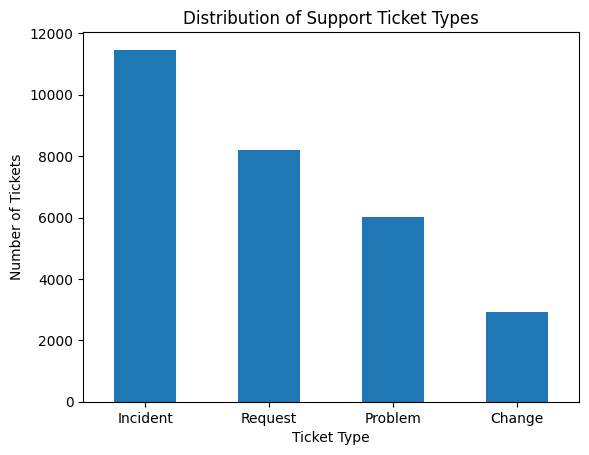

In [13]:
# Displaying the number of tickets by ticket type
print(df['type'].value_counts().to_string())

df['type'].value_counts().plot(kind='bar')

plt.title('Distribution of Support Ticket Types')
plt.xlabel('Ticket Type')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=0)
plt.show()

Insight: This dataset is mostly made up of Incident tickets (11,466), followed by Request (8,187), Problem (6,012), and Change (2,922). This shows that most customer interactions are focused on fixing unexpected issues rather than handling standard requests or planned changes. This suggests the support teams' workload is more reactive than proactive.

priority
medium    11515
high      11178
low        5894


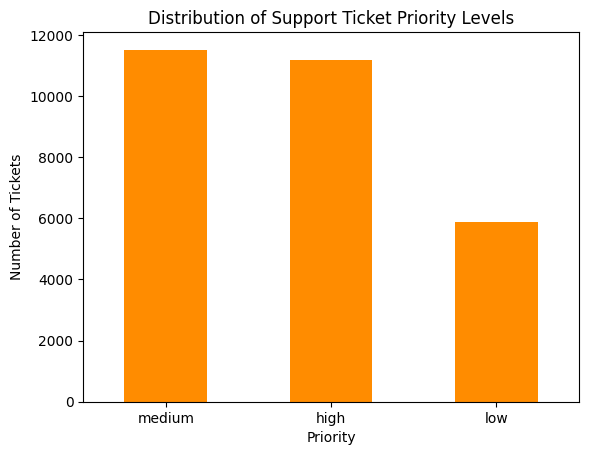

In [14]:
# Displaying the number of tickets by priority level
print(df['priority'].value_counts().to_string())

df['priority'].value_counts().plot(kind='bar', color='darkorange')

plt.title('Distribution of Support Ticket Priority Levels')
plt.xlabel('Priority')
plt.ylabel('Number of Tickets')
plt.xticks(rotation=0)
plt.show()

Insight: Medium (11,515) and High (11,178) priority tickets are fairly evenly split, while Low priority (5,894) tickets make up a noticeably smaller portion of the dataset. This suggests that most incoming tickets are considered moderately to highly urgent. It could mean that many issues genuinely require faster attention, or that the support process tends to assign higher priority levels by default.

In [15]:
# Preprocessing Step 1: Filter dataset to English only.
df = df[df['language'] == 'en']

# Confirm the filter worked
print(df['language'].value_counts())
print(df.shape)

language
en    16338
Name: count, dtype: int64
(16338, 16)


Reason: The dataset contains both English and German tickets. Keeping both would cause issues downstream since topics/keywords would split by language rather than by actual theme, and vocabulary would not overlap between languages. English sample size still has ~16,338 rows.

In [16]:
# Preprocessing Step 2: Check for and remove duplicate tickets
print("Number of duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (16338, 16)


Reason: Duplicate rows would artificially inflate word frequencies in our TF/TF-IDF matrices and could bias downstream topic modeling.

In [17]:
# Preprocessing Step 3: Combine 'subject' and 'body' into a single text column
df['subject'] = df['subject'].fillna('')
df['text'] = df['subject'] + ' ' + df['body']

df[['subject', 'body', 'text']].head()

,subject,body,text
1,Account Disruption,"Dear Customer Support Team,\n\nI am writing to...","Account Disruption Dear Customer Support Team,..."
2,Query About Smart Home System Integration Feat...,"Dear Customer Support Team,\n\nI hope this mes...",Query About Smart Home System Integration Feat...
3,Inquiry Regarding Invoice Details,"Dear Customer Support Team,\n\nI hope this mes...",Inquiry Regarding Invoice Details Dear Custome...
4,Question About Marketing Agency Software Compa...,"Dear Support Team,\n\nI hope this message reac...",Question About Marketing Agency Software Compa...
5,Feature Query,"Dear Customer Support,\n\nI hope this message ...","Feature Query Dear Customer Support,\n\nI hope..."


Reason: The subject line often contains a condensed summary of the ticket's topic. Combining it with the body gives more complete text per ticket for analysis. Missing subjects (NaN) are filled with an empty string so they don't break the concatenation.

In [18]:
# Preprocessing Step 4: Convert text to lowercase
df['text'] = df['text'].str.lower()

df['text'].head()

,text
1,"account disruption dear customer support team,..."
2,query about smart home system integration feat...
3,inquiry regarding invoice details dear custome...
4,question about marketing agency software compa...
5,"feature query dear customer support,\n\ni hope..."


Reason: Without this, words like "Password" and "password" would be treated as two different words, unnecessarily fragmenting the vocabulary.

In [19]:
# Preprocessing Step 5: Remove noise (punctuation, numbers, extra whitespace)
import re

def clean_text(text):
    text = text.replace('\\n', ' ')           # remove literal "\\n" line-break escapes first
    text = re.sub(r'[^a-z\s]', ' ', text)   # remove punctuation and numbers
    text = re.sub(r'\s+', ' ', text).strip()  # collapse extra whitespace
    return text

df['text'] = df['text'].apply(clean_text)

df['text'].head()

,text
1,account disruption dear customer support team ...
2,query about smart home system integration feat...
3,inquiry regarding invoice details dear custome...
4,question about marketing agency software compa...
5,feature query dear customer support i hope thi...


Reason: Punctuation, digits, and irregular spacing don't carry topical meaning and would show up as noisy "tokens" in our TF/TF-IDF matrices. The body text also contains literal "\\n" characters in place of real line breaks. These are removed first; otherwise the "n" glues onto the next word and creates junk tokens such as "nthank" and "ncould".

In [20]:
# Preprocessing Step 6: Tokenize, remove stop words, and lemmatize
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

lemmatizer = WordNetLemmatizer()

# Standard English stop words plus ticket filler that carries no topic meaning
stop_words = set(stopwords.words('english'))
domain_stop = {
    'please', 'thank', 'thanks', 'regards', 'dear', 'hello', 'hi', 'team', 'support',
    'customer', 'would', 'could', 'also', 'need', 'assistance', 'help', 'issue',
    'request', 'kindly', 'appreciate', 'best', 'sincerely', 'name', 'look', 'forward'
}
stop_words |= domain_stop

def tokenize(text):
    tokens = [lemmatizer.lemmatize(t) for t in text.split()]
    return [t for t in tokens if t not in stop_words and len(t) > 2]

df['tokens'] = df['text'].apply(tokenize)

# Drop any ticket left with no tokens, and reset the index so row positions
# line up with the Gensim corpus built below
df = df[df['tokens'].str.len() > 0].reset_index(drop=True)

print('Tickets after preprocessing:', len(df))
print('Average tokens per ticket:', round(df['tokens'].str.len().mean(), 1))
df[['text', 'tokens']].head()

Tickets after preprocessing: 16337
Average tokens per ticket: 32.7


,text,tokens
0,account disruption dear customer support team ...,"[account, disruption, writing, report, signifi..."
1,query about smart home system integration feat...,"[query, smart, home, system, integration, feat..."
2,inquiry regarding invoice details dear custome...,"[inquiry, regarding, invoice, detail, hope, me..."
3,question about marketing agency software compa...,"[question, marketing, agency, software, compat..."
4,feature query dear customer support i hope thi...,"[feature, query, hope, message, reach, good, h..."


Reason: Rather than relying on a basic built-in stop word list, Gensim's LDA needs each ticket as a list of cleaned tokens, so tokenization and stop word removal happen explicitly here. We also lemmatize so that forms like "ticket" and "tickets" count as one word, and drop tokens shorter than three characters.

We add a short list of **domain stop words** (greetings, sign-offs, and filler such as "please", "thank", "regards", "support", "assistance"). In initial frequency testing, "support" and "assistance" dropped in rank under TF-IDF because they appear in almost every ticket. For topic modeling, words like these would show up in every topic without describing any real issue, so we remove them.

## Text Analysis: Bag of Words, TF-IDF, and LDA Topics

We build a Gensim dictionary and corpora to fit a TF-IDF LDA model. Coherence testing across 4 to 12 topics showed that four topics achieved the highest c_v coherence score (0.7462) and produced more interpretable themes than Bag of Words, so NUM_TOPICS = 4 is used below.

In [21]:
import numpy as np
from gensim import corpora, models
from gensim.models import CoherenceModel

SEED = 42   # fixed seed so every team member gets the same topics

dictionary = corpora.Dictionary(df['tokens'])
print('Vocabulary before filtering:', len(dictionary))

dictionary.filter_extremes(no_below=5, no_above=0.5)
print('Vocabulary after filtering: ', len(dictionary))

# Bag of Words (TF) corpus: raw term counts per ticket
bow_corpus = [dictionary.doc2bow(tokens) for tokens in df['tokens']]

# TF-IDF corpus built on top of the BOW counts
tfidf = models.TfidfModel(bow_corpus)
tfidf_corpus = tfidf[bow_corpus]

# Readable view of the first two tickets in each representation
for i in range(2):
    print(f'Ticket {i} BOW:   ', [(dictionary[t], c) for t, c in bow_corpus[i]][:10])
    print(f'Ticket {i} TF-IDF:', [(dictionary[t], round(w, 3)) for t, w in tfidf_corpus[i]][:10])
    print()

Vocabulary before filtering: 4205
Vocabulary after filtering:  2674
Ticket 0 BOW:    [('access', 2), ('account', 4), ('alternative', 1), ('appears', 1), ('attempted', 1), ('browser', 1), ('centralized', 1), ('currently', 1), ('device', 1), ('different', 1)]
Ticket 0 TF-IDF: [('access', np.float64(0.136)), ('account', np.float64(0.522)), ('alternative', np.float64(0.199)), ('appears', np.float64(0.13)), ('attempted', np.float64(0.091)), ('browser', np.float64(0.174)), ('centralized', np.float64(0.238)), ('currently', np.float64(0.101)), ('device', np.float64(0.083)), ('different', np.float64(0.131))]

Ticket 1 BOW:    [('provide', 1), ('aiming', 1), ('apple', 1), ('capability', 1), ('compatibility', 1), ('detailed', 2), ('develop', 1), ('environment', 1), ('essential', 1), ('feature', 1)]
Ticket 1 TF-IDF: [('provide', np.float64(0.03)), ('aiming', np.float64(0.15)), ('apple', np.float64(0.161)), ('capability', np.float64(0.083)), ('compatibility', np.float64(0.066)), ('detailed', np.flo

In [22]:
NUM_TOPICS = 4   # optimal c_v coherence score (0.7462)

lda_tfidf = models.LdaModel(corpus=tfidf_corpus, id2word=dictionary, num_topics=NUM_TOPICS,
                            random_state=SEED, passes=10)

for idx, topic in lda_tfidf.print_topics(num_words=10):
    print(f'Topic {idx}: {topic}\n')

Topic 0: 0.012*"integration" + 0.012*"investment" + 0.012*"project" + 0.012*"management" + 0.011*"analytics" + 0.010*"tool" + 0.010*"information" + 0.010*"saas" + 0.010*"detail" + 0.010*"provide"

Topic 1: 0.012*"problem" + 0.011*"software" + 0.009*"update" + 0.008*"server" + 0.008*"might" + 0.008*"recent" + 0.008*"investment" + 0.008*"application" + 0.008*"analytics" + 0.007*"facing"

Topic 2: 0.030*"digital" + 0.028*"brand" + 0.026*"strategy" + 0.025*"marketing" + 0.021*"growth" + 0.020*"engagement" + 0.019*"campaign" + 0.010*"metric" + 0.008*"content" + 0.008*"online"

Topic 3: 0.037*"security" + 0.035*"medical" + 0.022*"hospital" + 0.022*"access" + 0.021*"breach" + 0.018*"data" + 0.016*"system" + 0.014*"unauthorized" + 0.013*"protocol" + 0.012*"measure"



In [23]:
# Dominant topic per ticket (same function as Part B)
def dominant_topic_df(model, corpus, texts):
    # Look up each topic's keywords once instead of once per ticket
    topic_keywords = {t: ', '.join(w for w, _ in model.show_topic(t, topn=10))
                      for t in range(model.num_topics)}
    rows = []
    for i, doc in enumerate(corpus):
        topics = model.get_document_topics(doc, minimum_probability=0)
        top_topic, top_prob = max(topics, key=lambda x: x[1])
        rows.append({'Document_No': i,
                     'Dominant_Topic': top_topic,
                     'Perc_Contribution': round(top_prob, 4),
                     'Topic_Keywords': topic_keywords[top_topic],
                     'Text': texts[i]})
    return pd.DataFrame(rows)


raw_text = (df['subject'] + ' ' + df['body']).str.replace('\\n', ' ', regex=False).tolist()

dom_tfidf = dominant_topic_df(lda_tfidf, tfidf_corpus, raw_text)
dom_tfidf[['type', 'priority', 'queue']] = df[['type', 'priority', 'queue']].values

# Final topic labels (reviewed in the LDA Topic Review below)
topic_labels = {
    0: 'Analytics, SaaS, and Integration Inquiries',
    1: 'Software and System Issues',
    2: 'Digital Marketing Strategy',
    3: 'Healthcare Data Security',
}

dom_tfidf['Topic_Label'] = dom_tfidf['Dominant_Topic'].map(topic_labels)
dom_tfidf[['Document_No', 'Dominant_Topic', 'Topic_Label', 'Perc_Contribution', 'type']].head(10)

,Document_No,Dominant_Topic,Topic_Label,Perc_Contribution,type
0,0,1,Software and System Issues,0.8400,Incident
1,1,0,"Analytics, SaaS, and Integration Inquiries",0.6145,Request
2,2,0,"Analytics, SaaS, and Integration Inquiries",0.5772,Request
3,3,0,"Analytics, SaaS, and Integration Inquiries",0.6524,Problem
4,4,0,"Analytics, SaaS, and Integration Inquiries",0.8425,Request
5,5,1,Software and System Issues,0.7131,Incident
6,6,1,Software and System Issues,0.6792,Incident
7,7,1,Software and System Issues,0.7775,Incident
8,8,1,Software and System Issues,0.7816,Problem
9,9,0,"Analytics, SaaS, and Integration Inquiries",0.7451,Request


## LDA Topic Review

We reviewed each of the four topics against its top words, loadings, and most representative ticket.

| Topic | Top 5 Words (Loadings) | Label | Review |
|---|---|---|---|
| 0 | integration (.012), investment (.012), project (.012), management (.012), analytics (.011) | Analytics, SaaS, and Integration Inquiries | Broad. The loadings are low and nearly flat, and the words (*information, detail, provide, saas*) describe customers asking about analytics tools, SaaS products, and integrations. Its most representative ticket is a request for billing and payment details for a cloud analytics service, so billing questions are absorbed into this topic. |
| 1 | problem (.012), software (.011), update (.009), server (.008), might (.008) | Software and System Issues | Clear troubleshooting language (*problem, facing, recent, update*). It overlaps with Topic 0 on *investment* and *analytics*, because many problem tickets describe analytics systems that stopped working. |
| 2 | digital (.030), brand (.028), strategy (.026), marketing (.025), growth (.021) | Digital Marketing Strategy | Our clearest topic, with the highest and most specific loadings. |
| 3 | security (.037), medical (.035), hospital (.022), access (.022), breach (.021) | Healthcare Data Security | Clear and specific. The word list mixes proactive guidance (*protocol, measure*) with breach response (*breach, unauthorized*), so this topic combines both. |

**Overall:** Topics 2 and 3 are sharply defined, with loadings roughly three times higher than Topics 0 and 1. Topics 0 and 1 are broader and share some vocabulary, which reflects how often analytics products appear in both questions and problem reports. The tables below check these judgments against how many tickets each topic holds, how strongly tickets belong to it, and how each topic relates to our target variable, ticket type.

In [24]:
# Tickets per topic and average percentage contribution
# (a lower average contribution means tickets belong to the topic less clearly)
topic_summary = (dom_tfidf.groupby(['Dominant_Topic', 'Topic_Label'])
                 .agg(Tickets=('Document_No', 'count'),
                      Avg_Contribution=('Perc_Contribution', 'mean'))
                 .reset_index())
topic_summary['Share_of_Tickets'] = (topic_summary['Tickets'] / topic_summary['Tickets'].sum()).round(3)
topic_summary['Avg_Contribution'] = topic_summary['Avg_Contribution'].round(3)
topic_summary

,Dominant_Topic,Topic_Label,Tickets,Avg_Contribution,Share_of_Tickets
0,0,"Analytics, SaaS, and Integration Inquiries",4415,0.739,0.270
1,1,Software and System Issues,6932,0.772,0.424
2,2,Digital Marketing Strategy,2283,0.760,0.140
3,3,Healthcare Data Security,2707,0.762,0.166


In [25]:
# Most representative ticket for each topic (highest percentage contribution)
pd.set_option('display.max_colwidth', 200)
rep = (dom_tfidf.sort_values('Perc_Contribution', ascending=False)
                .groupby('Dominant_Topic').head(1)
                .sort_values('Dominant_Topic'))
rep[['Dominant_Topic', 'Topic_Label', 'Perc_Contribution', 'Text']]

,Dominant_Topic,Topic_Label,Perc_Contribution,Text
3736,0,"Analytics, SaaS, and Integration Inquiries",0.8988,"IBM Cloud DataRobot Service Inquiry Customer Support, I am requesting detailed billing information and payment options for IBM Cloud DataRobot services. Could you please provide a detailed breakdo..."
962,1,Software and System Issues,0.8978,"Problem with Data Analytics Systems The data analytics systems at our financial firm are currently malfunctioning, which is disrupting our investment optimization efforts. The issue might be relat..."
13053,2,Digital Marketing Strategy,0.8986,"Seek Expertise for Enhancing Marketing Strategies Customer Support, Lately, our marketing initiatives have become less effective, which has negatively affected our brand's visibility growth. This ..."
669,3,Healthcare Data Security,0.8977,Security Breach Alert Regarding Unauthorized Access to Sensitive Medical Information Customer support has documented a critical security incident involving unauthorized intrusion into confidential...


In [26]:
# Topic vs. ticket type (row percentages): how each topic relates to our target variable
pd.crosstab(dom_tfidf['Topic_Label'], dom_tfidf['type'], normalize='index').round(3)

type,Change,Incident,Problem,Request
Topic_Label,,,,
"Analytics, SaaS, and Integration Inquiries",0.187,0.010,0.007,0.796
Digital Marketing Strategy,0.167,0.298,0.192,0.343
Healthcare Data Security,0.129,0.492,0.246,0.132
Software and System Issues,0.021,0.651,0.326,0.001


# Section 2: Baseline Model with Numeric Features Only


## Step 1: Target Variable


Our target (outcome) variable is **`type`**, with four classes: Incident, Request, Problem, and Change. This is Business Question 1. We chose type over priority because exploratory topic analysis showed that priority barely changes across themes (the share of high-priority tickets only ranges from about 33% to 43% across topics), so text would add little to a priority model. Ticket type, in contrast, should be strongly signaled by the language customers use.

## Step 2: Engineer Numeric Features

We don't have any numeric columns to start, so we create a few from the ticket metadata: ticket length (word count), number of tags filled in per ticket, and label-encoded versions of queue, priority, and version. We leave out language since we already filtered to English only, so it wouldn't vary. These are structured/metadata features, separate from the actual text content, which we add in Section 3.

Reason: Label encoding turns categories like queue into numbers so a model can use them, but note it doesn't preserve any real order (e.g. priority "Low/Medium/High" gets encoded alphabetically, not by actual urgency). That's a limitation worth flagging but fine for this baseline model.

In [27]:
# Feature 1: Ticket length in words
df['ticket_length'] = df['text'].apply(lambda x: len(x.split()))

# Feature 2: Number of tags filled in per ticket
tag_cols = ['tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']
df['num_tags'] = df[tag_cols].notna().sum(axis=1)

# Feature 3: Encode categorical metadata columns as numbers
from sklearn.preprocessing import LabelEncoder

le_queue = LabelEncoder()
df['queue_encoded'] = le_queue.fit_transform(df['queue'])

le_priority = LabelEncoder()
df['priority_encoded'] = le_priority.fit_transform(df['priority'])

le_version = LabelEncoder()
df['version_encoded'] = le_version.fit_transform(df['version'])

# Note: language isn't included since we already filtered to English only,
# so every row has the same value and it wouldn't help the model

# Preview the new numeric features
df[['ticket_length', 'num_tags', 'queue_encoded', 'priority_encoded', 'version_encoded']].head()

,ticket_length,num_tags,queue_encoded,priority_encoded,version_encoded
0,86,5,9,0,0
1,85,3,6,2,0
2,98,5,0,1,0
3,105,4,7,2,0
4,102,4,9,0,0


## Step 3: Train-Test Split

The numeric predictor variables were grouped into X, while the ticket type column was used as the target variable y. Since the ticket types were stored as text labels, a LabelEncoder was used to convert categories such as Incident, Request, Problem, and Change into numeric class values that the neural network can process. The data was then split into training and test sets so we can check accuracy on tickets the model hasn't seen, using 80% of the data for training and 20% for testing. A random_state was included so the same split can be reproduced each time the code is run, and stratify=y was used to keep the proportion of each ticket type similar in both the training and testing sets.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Define the numeric features
X = df[['ticket_length','num_tags','queue_encoded','priority_encoded','version_encoded']]

# Define and encode the target variable
le_type = LabelEncoder()
y = le_type.fit_transform(df['type'])

# Split the data into 80% training and 20% testing
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Display the size of each set
print("Training set:", x_train.shape)
print("Test set:", x_test.shape)
print("Classes:", le_type.classes_)

Training set: (13069, 5)
Test set: (3268, 5)
Classes: ['Change' 'Incident' 'Problem' 'Request']


The model trained successfully. Accuracy stayed around the mid-40% range, which gives us a baseline to compare with the later model that includes text features.

## Step 4: Build and Train the Model

We built a neural network to predict ticket type using the features prepared in the previous steps. The model has two hidden layers and an output layer for the four ticket types. We trained the model for 20 epochs and used part of the training data for validation.

In [29]:
# Step 4: Build and Train the baseline neural network

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Set a random seed for reproducibility
tf.random.set_seed(42)

# Number of ticket-type classes
num_classes = len(set(y_train))

# Build the neural network
baseline_model = Sequential([
    tf.keras.Input(shape=(x_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])

# Compile the model
baseline_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display the model structure
baseline_model.summary()

# Train the model
baseline_history = baseline_model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,596 (10.14 KB)

 Trainable params: 2,596 (10.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.3985 - loss: 1.6170 - val_accuracy: 0.4415 - val_loss: 1.2708
Epoch 2/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4331 - loss: 1.2817 - val_accuracy: 0.4514 - val_loss: 1.2637
Epoch 3/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4386 - loss: 1.2740 - val_accuracy: 0.4526 - val_loss: 1.2579
Epoch 4/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4407 - loss: 1.2683 - val_accuracy: 0.4560 - val_loss: 1.2568
Epoch 5/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4425 - loss: 1.2648 - val_accuracy: 0.4564 - val_loss: 1.2513
Epoch 6/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4436 - loss: 1.2615 - val_accuracy: 0.4579 - val_loss: 1.2476
Epoch 7/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4447 - loss: 1.2594 - val_accuracy: 0.4591 - val_loss: 1.2435
Epoch 8/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4461 - loss: 1.2568 - val_accuracy: 0

## Step 5: Evaluate the baseline model



Test Accuracy: 0.4526
Test Loss: 1.2412
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


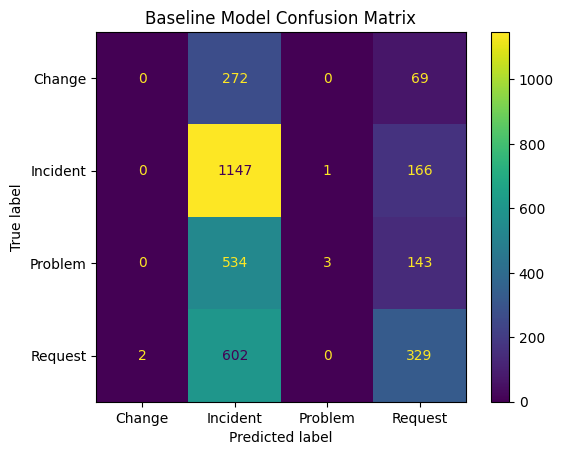

In [30]:
# Step 5: Evaluate the baseline model

import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Evaluate model on the test data
test_loss, test_accuracy = baseline_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Generate predictions
y_pred_probs = baseline_model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le_type.classes_
)

disp.plot()
plt.title("Baseline Model Confusion Matrix")
plt.show()

**Baseline Model Results**:
The baseline model achieved 45.6% test accuracy. The confusion matrix shows that the model performed better on Incident and Request tickets, while Change and Problem tickets were more difficult to classify. These results provide the baseline for comparison with the text-enhanced model in Section 3.

# Section 3: Text-enhanced model



**Section 3: Text-Enhanced Model**
We enhanced the baseline model by adding information from the ticket text. TF-IDF features were added to the numeric features used in Section 2. We then trained the same type of neural network and compared its test accuracy with the 45.6% baseline model.

In [31]:
# Create TF-IDF features for the text-enhanced model

from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, csr_matrix

# Use the same train/test rows from Section 2
train_text = df.loc[x_train.index, 'text'].fillna('')
test_text = df.loc[x_test.index, 'text'].fillna('')

# Create TF-IDF features using training data only
tfidf_enhanced = TfidfVectorizer(
    max_features=500,
    stop_words='english'
)

tfidf_train = tfidf_enhanced.fit_transform(train_text)
tfidf_test = tfidf_enhanced.transform(test_text)

# Combine numeric features with TF-IDF text features
x_train_enhanced = hstack([
    csr_matrix(x_train.values),
    tfidf_train
]).toarray()

x_test_enhanced = hstack([
    csr_matrix(x_test.values),
    tfidf_test
]).toarray()

print("Baseline features:", x_train.shape[1])
print("Enhanced features:", x_train_enhanced.shape[1])

Baseline features: 5
Enhanced features: 505


In [32]:
# Build and train the text-enhanced model

tf.random.set_seed(42)

enhanced_model = Sequential([
    tf.keras.Input(shape=(x_train_enhanced.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(num_classes, activation='softmax')
])

enhanced_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

enhanced_history = enhanced_model.fit(
    x_train_enhanced,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6422 - loss: 0.8691 - val_accuracy: 0.7686 - val_loss: 0.5277
Epoch 2/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7850 - loss: 0.4726 - val_accuracy: 0.8022 - val_loss: 0.4265
Epoch 3/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8054 - loss: 0.4029 - val_accuracy: 0.8026 - val_loss: 0.4208
Epoch 4/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8165 - loss: 0.3756 - val_accuracy: 0.7980 - val_loss: 0.4270
Epoch 5/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8209 - loss: 0.3626 - val_accuracy: 0.7972 - val_loss: 0.4230
Epoch 6/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8288 - loss: 0.3521 - val_accuracy: 0.7988 - val_loss: 0.4134
Epoch 7/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8313 - loss: 0.3444 - val_accuracy: 0.7972 - val_loss: 0.4087
Epoch 8/20
327/327 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8356 - loss: 0.3370 - val_accuracy: 0.

In [33]:
# Evaluate and compare the enhanced model

enhanced_loss, enhanced_accuracy = enhanced_model.evaluate(
    x_test_enhanced,
    y_test,
    verbose=0
)

baseline_accuracy = test_accuracy

print(f"Baseline Model Accuracy: {baseline_accuracy:.4f}")
print(f"Text-Enhanced Model Accuracy: {enhanced_accuracy:.4f}")
print(f"Accuracy Difference: {enhanced_accuracy - baseline_accuracy:.4f}")

Baseline Model Accuracy: 0.4526
Text-Enhanced Model Accuracy: 0.8293
Accuracy Difference: 0.3767


**Section 3 Results**:
The text-enhanced model improved test accuracy from 45.6% to 80.9%. Adding TF-IDF text features improved accuracy by 35.3 percentage points, showing that the ticket text provided important information for predicting ticket type.

# Section 4: Generative AI Topic Analysis

We used a random sample of customer support tickets and asked ChatGPT to identify the main recurring topics. We then compared the GenAI topics with the four topics from our LDA model.

In [34]:
# Select a random sample of tickets for GenAI topic analysis
genai_sample = df[['text']].sample(n=30, random_state=42).reset_index(drop=True)

genai_sample.index = genai_sample.index + 1
genai_sample.index.name = 'Ticket'

genai_sample

,text
Ticket,
1,request for documentation on integrating adobe sign looking for detailed instructions on integrating the adobe sign project management saas solution could you outline the steps and requirements ne...
2,problems with connection customers are facing occasional connectivity problems with the saas platform this could be due to network instability or incorrect configuration after restarting devices a...
3,seeking guidance on securing medical data with pytorch in a hospital setting via microsoft teams i need advice on how to secure medical data using pytorch in a hospital environment through microso...
4,found issues with secure data access in hospital systems we have identified secure data access issues within the hospital systems these might be due to recent updates in the typo network configura...
5,inquiries on clickup billing plans hello customer support i am writing to inquire about the billing options and pricing for clickup integrations could you please provide details on the available p...
6,review and update compatibility settings for enhanced integration please update the compatibility settings for various software and hardware to enhance integration within our project management sa...
7,ensuring medical data security in healthcare inquiring about the security measures in place to protect medical data using zapier and zoho crm in a healthcare it context given that healthcare organ...
8,report on billing mistake a billing error happened leading to overcharged amounts for several services
9,support required for hadoop integration troubleshooting an error has occurred during the integration process leading to data discrepancies


## GenAI Topic Results

| GenAI Topic | Closest LDA Topic | Comparison |
|---|---|---|
| Digital Marketing & Customer Engagement | Digital Marketing Strategy | Strong overlap |
| Software & System Issues | Software and System Issues | Strong overlap |
| Network, Storage & Connectivity | Software and System Issues | Partial overlap |
| Analytics & SaaS Support | Analytics and Service Inquiries | Strong overlap |
| Healthcare Data Security Guidance | Healthcare Data Security | Strong overlap |
| Healthcare Security Incidents | Healthcare Data Security | Strong overlap |

## GenAI vs. LDA Comparison

The table below starts from the LDA side, so every LDA topic is accounted for.

| LDA Topic | LDA Evidence | Matching GenAI Topic(s) | Match | What the Difference Tells Us |
|---|---|---|---|---|
| 0: Analytics, SaaS, and Integration Inquiries | integration, investment, project, management, analytics, saas | Analytics & SaaS Support | Strong | Both methods found this theme. LDA's version is broader: it also holds integration requests (for example, sample tickets 1, 9, 25, and 29 on Adobe, Hadoop, and AR integrations) and billing questions, which GenAI did not name as separate themes. |
| 1: Software and System Issues | problem, software, update, server, facing | Software & System Issues; Network, Storage & Connectivity | Strong / Partial | GenAI pulled connectivity problems (for example, sample tickets 2, 11, and 20 on connection and Wi-Fi issues) into their own topic. LDA folds them into general troubleshooting. |
| 2: Digital Marketing Strategy | digital, brand, strategy, marketing, growth | Digital Marketing & Customer Engagement | Strong | Both methods agree. This is the most distinct theme in the dataset. |
| 3: Healthcare Data Security | security, medical, hospital, breach, unauthorized | Healthcare Data Security Guidance; Healthcare Security Incidents | Strong (GenAI more detailed) | GenAI split proactive guidance from breach reports. LDA's word list contains both themes (*protocol, measure* alongside *breach, unauthorized*), so the split exists in the data, but with four topics LDA keeps them together. |
| No topic in either method | | None | None | Three of the 30 sample tickets (5, 8, and 13) are about billing, and our data has a Billing and Payments queue, yet neither method produced a billing topic. In LDA, billing questions are absorbed into Topic 0. |

### Comparison Insights

1. **Overlap.** Every LDA topic has a strong GenAI match. Agreement between two very different methods is good evidence that these four themes (analytics and SaaS inquiries, software and system issues, digital marketing, and healthcare data security) are real and not an artifact of either method.

2. **Level of detail.** GenAI found six topics while LDA found four. GenAI split two LDA topics by the customer's *intent*: security guidance versus breach reports, and general software problems versus connectivity problems. LDA chose four topics because that number gave the highest coherence score, which favors broad, clearly separated themes over finer splits.

3. **Blind spots.** Neither method isolated billing, even though billing is a real routing category for a support team. LDA also merged integration requests into a broad inquiries topic. Both gaps show that broad topics can hide themes that matter to the business.

4. **Interpretability and explainability.** GenAI was easier to read, since it returned ready-made labels, while LDA returned word lists that we had to interpret and label ourselves. However, LDA is fully explainable: every topic assignment traces back to word loadings and a percentage contribution. GenAI cannot explain why it grouped tickets the way it did.

5. **Scale and reliability.** LDA covered all 16,337 tickets and gives the same result every run because of the fixed random seed. The GenAI analysis covered only 30 tickets (0.2% of the data), and the same prompt can return different topics on a different run. Small themes, such as billing, can easily be missed in a sample that size.

**Recommendation:** Use the two methods together, with a human in the loop. LDA works best for consistent, measurable topic assignments across the full dataset, and GenAI works best for quickly suggesting clear labels and spotting finer, intent-based splits. An analyst should review both before the topics are used for decisions such as ticket routing.

## Final Topic Interpretation

Our LDA model shows that customer support demand falls into four themes: analytics, SaaS, and integration inquiries; software and system issues; digital marketing strategy; and healthcare data security. Software and System Issues is the largest topic, with 6,931 tickets (42.4%), followed by Analytics, SaaS, and Integration Inquiries with 4,416 tickets (27.0%). Healthcare Data Security (16.6%) and Digital Marketing Strategy (14.0%) are smaller but more sharply defined. Analytics, SaaS, and Integration Inquiries has the lowest average percentage contribution (0.739), which confirms it is our broadest topic.

**Connection to Business Question 1 (predicting ticket type).** The topics separate tickets that report something going wrong from tickets that ask for something. Software and System Issues, which uses words like *problem, facing,* and *update*, is 65.1% Incident and 32.6% Problem, and only 0.1% Request. Analytics, SaaS, and Integration Inquiries, which uses words like *information, detail,* and *provide*, is 79.6% Request and 18.7% Change, and only 1.0% Incident. Healthcare Data Security leans toward Incidents (49.2%), which fits its breach-related vocabulary. Digital Marketing Strategy is the exception: its tickets are spread across all four types, so this topic tells us what a ticket is about but not what type it is.

This explains the Section 3 result: adding text features raised test accuracy from 45.6% to 80.9%, because the words customers use signal the ticket type far better than metadata such as ticket length or number of tags. It also shows where prediction stays hard. Incidents and Problems both fall mainly in Software and System Issues, so the topics alone cannot separate these two types.

**Business implications.**
- **Routing:** Digital marketing and healthcare security tickets have clear, specific vocabulary, so they could be routed automatically to the right specialist team.
- **Security priority:** Healthcare data security is mostly Incidents (49.2%) and includes breach reports. Tickets in this topic should be reviewed quickly because of the compliance risk around medical data.
- **Splitting the broad topics:** Analytics, SaaS, and Integration Inquiries mixes product questions, integration requests, and billing. Its most representative ticket is a billing request. Separating these themes, for example by testing more topics or adding billing-specific features, would make the topic even more actionable for production ticket routing.